# A4. 학습: 손실, 사전 학습, SFT, RLHF, RLVR

- 영상: [36:01 Pretraining & mid-training](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=2161s), [44:21 Post-training](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=2661s), [47:33 Training LLMs for coding agents](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=2853s) ~ 52:30
- 슬라이드: `data/lecture02.pdf` 92–118쪽 [1]

## 목표

1. 학습의 목표인 **손실**(cross-entropy)을 손으로 계산하고, 손실을 줄이는 방법(**경사 하강**)을 그림으로 봅니다.
2. 사전 학습 데이터를 거르는 과정을 장난감 크기로 따라 하고, 작은 모델을 몇 분 동안 **사전 학습**합니다.
3. 외우기만 하는 상태(**과적합**)를 일부러 만들어 봅니다.
4. GPT-2에 덧셈 문답을 **SFT**로 가르치고, 질문 토큰을 손실에서 빼는 방법을 봅니다.
5. **RLHF**의 흐름을 그림으로 보고, 자동 채점 보상(**RLVR**)으로 GPT-2를 강화학습해 정답률이 오르는 것을 봅니다.

**이 노트북이 답하는 질문**: 아무것도 모르는 모델이 어떤 단계를 거쳐 "질문에 맞게 답하는" 모델이 되나?

문장 끝의 `[번호]`는 맨 아래 **출처** 절의 번호입니다. "이 노트북의 결과"라고 적은 것은 여기서 직접 돌린 실험 결과입니다.

In [1]:
# 그림 도구: 펼치지 않아도 됩니다. 아래 본문 셀은 이 함수들을 한 줄씩 부릅니다.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False})
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "red": "#D55E00", "pink": "#CC79A7", "black": "#000000", "grey": "#BBBBBB"}   # Okabe-Ito


def _box(ax, x, y, w, h, text, color, fs=9.5, tc="black"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec="#555555", lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=tc)


def _arrow(ax, x0, y0, x1, y1, text=None):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.3))
    if text:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.12, text, ha="center", va="bottom", fontsize=8.5, color="#444444")


def flow(steps, notes=None, colors=None, ncol=4, title=None, w=2.3, h=0.9, figw=13):
    """steps 를 ncol 개씩 뱀 모양(다음 줄은 오른쪽에서 왼쪽)으로 상자-화살표로 그린다."""
    n = len(steps)
    nrow = (n + ncol - 1) // ncol
    fig, ax = plt.subplots(figsize=(figw, 1.75 * nrow + 0.3))
    pos = []
    for i in range(n):
        r, c = divmod(i, ncol)
        c = c if r % 2 == 0 else ncol - 1 - c
        pos.append((c * 3.2, -r * 1.75))
    for i, ((x, y), s) in enumerate(zip(pos, steps)):
        _box(ax, x, y, w, h, s, colors[i] if colors else OI["sky"])
        if notes and notes[i]:
            ax.text(x, y - h / 2 - 0.08, notes[i], ha="center", va="top", fontsize=8.5, color="#333333")
    for i in range(n - 1):
        (x0, y0), (x1, y1) = pos[i], pos[i + 1]
        if y0 == y1:
            d = 1 if x1 > x0 else -1
            _arrow(ax, x0 + d * w / 2, y0, x1 - d * w / 2, y1)
        else:
            _arrow(ax, x0 + w / 2 + 0.05, y0, x1 + w / 2 + 0.05, y1)
    ax.set_xlim(-w / 2 - 0.2, (ncol - 1) * 3.2 + w / 2 + 0.3)
    ax.set_ylim(-(nrow - 1) * 1.75 - h / 2 - 0.45, h / 2 + 0.15)
    ax.axis("off")
    if title:
        ax.set_title(title)
    fig.tight_layout()
    plt.show()


def draw_ce(tokens, probs, correct):
    probs = np.asarray(probs)
    other = 1 - probs.sum()
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.0), gridspec_kw={"width_ratios": [1.25, 1]})
    labels = list(tokens) + ["(all other\ntokens)"]
    vals = list(probs) + [other]
    cols = [OI["red"] if t == correct else OI["grey"] for t in tokens] + ["#E5E5E5"]
    x = np.arange(len(labels))
    ax[0].bar(x, vals, color=cols)
    for i, v in enumerate(vals):
        ax[0].text(i, v + 0.012, f"{v:.4f}" if i < len(tokens) else f"{v:.2f}", ha="center", va="bottom", fontsize=8.5)
    onehot = [1 if t == correct else 0 for t in tokens] + [0]
    for i, o in enumerate(onehot):
        ax[0].text(i, -0.13, str(o), ha="center", va="center", fontsize=11, fontweight="bold",
                   color=OI["red"] if o else "#777777")
    ax[0].text(-0.9, -0.13, "one-hot y:", ha="right", va="center", fontsize=9)
    ax[0].set_xticks(x, labels)
    ax[0].set_ylim(-0.2, max(vals) * 1.25)
    ax[0].axhline(0, color="black", lw=0.8)
    ax[0].set_ylabel("model probability p")
    ax[0].set_title("A. Next token after 'The class was about'")
    p = np.logspace(-3, 0, 200)
    ax[1].plot(p, -np.log(p), color=OI["blue"], label="loss = -ln p (PyTorch)")
    ax[1].plot(p, -np.log10(p), color=OI["orange"], ls="--", label="-log10 p (slide 99)")
    pc = float(probs[list(tokens).index(correct)])
    for q, lab in [(pc, f"p={pc}"), (0.32, "p=0.32"), (0.9, "p=0.9")]:
        ax[1].plot(q, -np.log(q), "o", color=OI["red"] if q == pc else OI["blue"])
        ax[1].text(q * 1.15, -np.log(q) + 0.15, f"{lab}\nloss {-np.log(q):.2f}", fontsize=8.5)
    ax[1].set_xscale("log")
    ax[1].set_xlabel("probability given to the correct token (log scale)")
    ax[1].set_ylabel("loss")
    ax[1].set_title("B. Lower probability -> bigger loss")
    ax[1].legend(frameon=False, fontsize=8.5, loc="upper right")
    fig.tight_layout()
    plt.show()


def draw_gd(runs, w_min=3.0):
    """runs: [(lr, [w0, w1, ...]), ...]  손실 L(w) = (w - 3)^2 + 1 위의 경사 하강 경로"""
    L = lambda w: (np.asarray(w) - w_min) ** 2 + 1
    fig, axes = plt.subplots(1, len(runs), figsize=(4.2 * len(runs), 3.8), sharey=True)
    ww = np.linspace(-1.5, 7.5, 300)
    for ax, (lr, path) in zip(axes, runs):
        ax.plot(ww, L(ww), color="#888888")
        path = np.asarray(path)
        ax.plot(path, L(path), "o", color=OI["blue"], ms=5, zorder=3)
        for a, b in zip(path[:-1], path[1:]):
            ax.annotate("", xy=(b, L(b)), xytext=(a, L(a)),
                        arrowprops=dict(arrowstyle="-|>", color=OI["red"], lw=1.1))
        ax.plot(w_min, 1, "*", color=OI["green"], ms=14, zorder=4)
        ax.text(path[0], L(path[0]) + 1.2, "start", ha="center", fontsize=8.5)
        ax.set_title(f"learning rate {lr}: {len(path) - 1} steps")
        ax.set_xlabel("parameter w")
        ax.set_ylim(0, 22)
    axes[0].set_ylabel("loss L(w) = (w - 3)^2 + 1")
    fig.tight_layout()
    plt.show()


def draw_pipeline(stages, counts, removed):
    fig, ax = plt.subplots(figsize=(13, 2.5))
    n = len(stages)
    for i, (s, c, r) in enumerate(zip(stages, counts, removed)):
        x = i * 2.7
        _box(ax, x, 0, 2.1, 1.0, f"{s}\n{c} docs", OI["sky"] if i < n - 1 else OI["green"])
        if r:
            ax.text(x, -0.7, r, ha="center", va="top", fontsize=8.5, color=OI["red"])
        if i < n - 1:
            _arrow(ax, x + 1.05, 0, x + 2.7 - 1.05, 0)
    ax.set_xlim(-1.3, (n - 1) * 2.7 + 1.3)
    ax.set_ylim(-1.25, 0.65)
    ax.axis("off")
    ax.set_title("Toy pretraining data pipeline (this notebook's 10 documents)")
    fig.tight_layout()
    plt.show()


def draw_mix(mixes):
    """mixes: {"label": {"web": .., "code": .., ...}}  -- 예시 숫자(실제 모델 값 아님)"""
    cats = list(next(iter(mixes.values())).keys())
    cols = [OI["grey"], OI["blue"], OI["orange"], OI["green"], OI["pink"]]
    fig, ax = plt.subplots(figsize=(10, 2.9))
    for j, (lab, m) in enumerate(mixes.items()):
        left = 0
        for c, col in zip(cats, cols):
            ax.barh(j, m[c], left=left, color=col, edgecolor="white", label=c if j == 0 else None)
            if m[c] >= 0.08:
                ax.text(left + m[c] / 2, j, f"{c}\n{m[c]:.0%}", ha="center", va="center", fontsize=8.5)
            left += m[c]
    ax.set_yticks(range(len(mixes)), list(mixes))
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of training tokens (ILLUSTRATIVE numbers, not a real model)")
    ax.spines["left"].set_visible(False)
    ax.legend(ncol=len(cats), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()


def draw_overfit(full, small, small_chars):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for a, (lg, ttl) in zip(ax, [(full, "A. all training text (~1M chars)"), (small, f"B. only {small_chars:,} chars")]):
        a.plot(lg["step"], lg["train"], "o-", color=OI["blue"], ms=3, label="train loss")
        a.plot(lg["step"], lg["val"], "o-", color=OI["red"], ms=3, label="validation loss")
        i = int(np.argmin(lg["val"]))
        a.plot(lg["step"][i], lg["val"][i], "*", color=OI["green"], ms=13, zorder=4)
        a.text(lg["step"][i], lg["val"][i] - 0.25, "best validation", ha="center", va="top", fontsize=8.5)
        a.set_title(ttl)
        a.set_xlabel("training step")
    ax[0].set_ylabel("cross-entropy (nats per char)")
    ax[0].legend(frameon=False)
    fig.tight_layout()
    plt.show()


def draw_mask(tokens, labels):
    n = len(tokens)
    fig, ax = plt.subplots(figsize=(min(1.0 * n + 1.5, 15), 2.6))
    for i, (t, l) in enumerate(zip(tokens, labels)):
        used = l != -100
        _box(ax, i, 0.6, 0.9, 0.7, t.replace("\n", "\\n"), OI["orange"] if used else "#E5E5E5", fs=9)
        ax.text(i, -0.05, str(l), ha="center", va="center", fontsize=8.5, color=OI["red"] if used else "#777777")
    ax.text(-0.6, 0.6, "token", ha="right", va="center", fontsize=9)
    ax.text(-0.6, -0.05, "label", ha="right", va="center", fontsize=9)
    ax.text(n / 2 - 0.5, -0.55, "grey = label -100 (ignored by the loss)    orange = counted in the loss",
            ha="center", va="center", fontsize=9)
    ax.set_xlim(-2.2, n - 0.4)
    ax.set_ylim(-0.8, 1.1)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def draw_rlhf():
    fig = plt.figure(figsize=(13, 3.4))
    ax = fig.add_axes([0.0, 0.0, 0.66, 1.0])
    steps = [("1. SFT", "people write good\nanswers -> fine-tune"),
             ("2. Reward model", "people rank 4-9 answers,\nturned into A > B pairs\n-> model learns a score r"),
             ("3. RL (PPO)", "LM writes answers,\nreward model scores them,\nLM is pushed to higher r")]
    for i, (t, d) in enumerate(steps):
        x = i * 3.0
        _box(ax, x, 0.55, 2.4, 0.75, t, [OI["sky"], OI["yellow"], OI["orange"]][i], fs=10.5)
        ax.text(x, 0.0, d, ha="center", va="top", fontsize=9)
        if i < 2:
            _arrow(ax, x + 1.2, 0.55, x + 3.0 - 1.2, 0.55)
    ax.set_xlim(-1.4, 7.4); ax.set_ylim(-1.1, 1.2); ax.axis("off")
    ax2 = fig.add_axes([0.72, 0.17, 0.26, 0.7])
    d = np.linspace(-5, 5, 200)
    ax2.plot(d, 1 / (1 + np.exp(-d)), color=OI["blue"])
    ax2.axhline(0.5, color="#999999", ls=":", lw=1)
    ax2.set_xlabel("r(A) - r(B)")
    ax2.set_ylabel("P(people prefer A)")
    ax2.set_title("Reward model: sigmoid of score gap", fontsize=10)
    plt.show()


def draw_rlvr(prompt, answers, truth, rewards):
    fig, ax = plt.subplots(figsize=(13, 3.4))
    _box(ax, 0, 0, 2.6, 1.0, prompt.replace("\nAnswer:", "\nAnswer: ?"), OI["sky"], fs=8.5)
    _arrow(ax, 1.3, 0, 2.2, 0, "sample 8")
    for i, (a, r) in enumerate(zip(answers, rewards)):
        x = 3.0 + i * 1.05
        _box(ax, x, 0, 0.9, 0.6, a.strip()[:6] or "(empty)", OI["green"] if r else "#E5E5E5", fs=9)
        ax.text(x, -0.55, f"r={int(r)}", ha="center", fontsize=9, color=OI["green"] if r else "#777777")
    ax.text(3.0 + 3.5 * 1.05, 0.65, f"checker: is it exactly {truth}?  (no human, no reward model)",
            ha="center", fontsize=9.5)
    ax.set_xlim(-1.4, 3.0 + 8 * 1.05)
    ax.set_ylim(-1.0, 1.0)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def draw_reinforce(names, samples, rewards, adv, hist, hist_low=None, correct=0):
    hist = np.asarray(hist)
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.1, 1, 1.1]})
    x = np.arange(len(samples))
    ax[0].bar(x, adv, color=[OI["green"] if a > 0 else OI["red"] if a < 0 else OI["grey"] for a in adv])
    for i, (s, r) in enumerate(zip(samples, rewards)):
        ax[0].text(i, 0, f"{names[s]}\nr={int(r)}", ha="center", va="bottom" if adv[i] < 0 else "top", fontsize=8.5)
    ax[0].axhline(0, color="black", lw=0.8)
    ax[0].set_xticks(x, [f"#{i+1}" for i in x])
    ax[0].set_ylabel("advantage = reward - group mean")
    ax[0].set_title("A. First step with a correct sample")
    w = 0.38
    k = np.arange(len(names))
    ax[1].bar(k - w / 2, hist[0], w, color=OI["grey"], label="before")
    ax[1].bar(k + w / 2, hist[-1], w, color=OI["blue"], label=f"after {len(hist) - 1} steps")
    ax[1].set_xticks(k, [f"'{n}'" + (" (correct)" if i == correct else "") for i, n in enumerate(names)])
    ax[1].set_ylabel("policy probability")
    ax[1].set_title("B. Answer probabilities")
    ax[1].legend(frameon=False)
    ax[2].plot(hist[:, correct], "o-", color=OI["green"], ms=3, label=f"start P = {hist[0, correct]:.2f}")
    if hist_low is not None:
        hist_low = np.asarray(hist_low)
        ax[2].plot(hist_low[:, correct], "o-", color=OI["red"], ms=3, label=f"start P = {hist_low[0, correct]:.3f}")
        ax[2].legend(frameon=False, fontsize=8.5, loc="lower right")
    ax[2].set_xlabel("update step")
    ax[2].set_ylabel(f"P('{names[correct]}')")
    ax[2].set_ylim(0, 1.02)
    ax[2].set_title("C. Probability of the correct answer")
    fig.tight_layout()
    plt.show()

In [2]:
import os, warnings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")          # 설치 환경에 따라 나오는 경고 문구를 숨긴다

import copy, hashlib, html, math, random, re, time, urllib.request
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); random.seed(0); np.random.seed(0)
os.makedirs("data", exist_ok=True)

## 개념 지도

이 노트북의 단계가 어떻게 이어지는지 먼저 봅니다. 위 줄이 **사전 학습**(대량의 글로 다음 토큰 맞히기), 아래 줄이 **사후 학습**(post-training, 원하는 행동을 가르치기)입니다 [1, 92–118쪽].

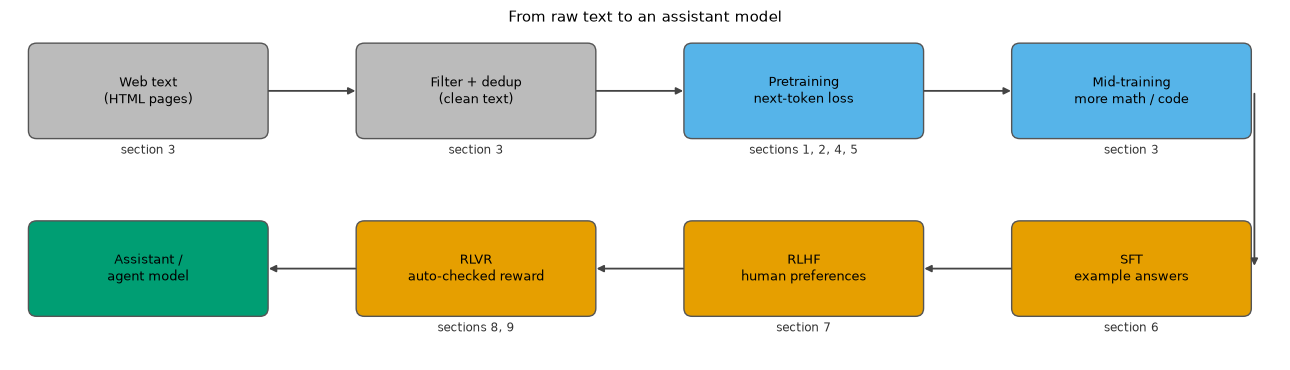

In [3]:
flow(["Web text\n(HTML pages)", "Filter + dedup\n(clean text)", "Pretraining\nnext-token loss", "Mid-training\nmore math / code",
      "SFT\nexample answers", "RLHF\nhuman preferences", "RLVR\nauto-checked reward", "Assistant /\nagent model"],
     notes=["section 3", "section 3", "sections 1, 2, 4, 5", "section 3",
            "section 6", "section 7", "sections 8, 9", ""],
     colors=[OI["grey"], OI["grey"], OI["sky"], OI["sky"], OI["orange"], OI["orange"], OI["orange"], OI["green"]],
     title="From raw text to an assistant model")

**그림에서 볼 것**
- 회색은 데이터 준비, 파랑은 사전 학습 계열, 주황은 사후 학습입니다.
- 모든 단계가 결국 "손실을 줄이도록 파라미터를 조금씩 고친다"는 같은 원리로 돕니다. 그래서 손실과 경사 하강부터 봅니다.

## 1. 손실(loss)과 cross-entropy

**한 줄 정의**: 손실은 "모델이 얼마나 틀렸는지"를 숫자 하나로 나타낸 것입니다. 언어 모델에서는 정답 토큰에 준 확률 $p$로 $-\log p$를 씁니다 [1, 99–100쪽]. 슬라이드 100쪽 식의 log에는 밑이 적혀 있지 않고, PyTorch는 자연로그 $\ln$을 씁니다 [6].

**왜 필요한가**: 파라미터가 1억 개가 넘는 모델을 고치려면 "지금 얼마나 틀렸고, 어느 쪽으로 고치면 덜 틀리는지"를 숫자로 알아야 합니다. 그 숫자가 손실입니다.

**숫자로 따라가기**: 슬라이드 17쪽은 "The class was about" 다음 토큰 후보의 확률을 보여 줍니다 [1, 17쪽]. 실제 글의 다음 토큰은 "how"였습니다 [1, 98쪽].

| 후보 토큰 | 모델 확률 $p$ | one-hot $y$ (정답만 1) | $y \times (-\ln p)$ |
|---|---|---|---|
| to | 0.3171 | 0 | 0 |
| as | 0.0491 | 0 | 0 |
| the | 0.0360 | 0 | 0 |
| a | 0.0330 | 0 | 0 |
| two | 0.0147 | 0 | 0 |
| how | 0.0124 | **1** | $-\ln 0.0124 = $ **4.39** |

정답이 아닌 줄은 $y=0$이라 모두 0이 되고, 정답 줄 하나만 남습니다. 그래서 손실은 $-\ln p_{\text{정답}}$ 하나입니다.

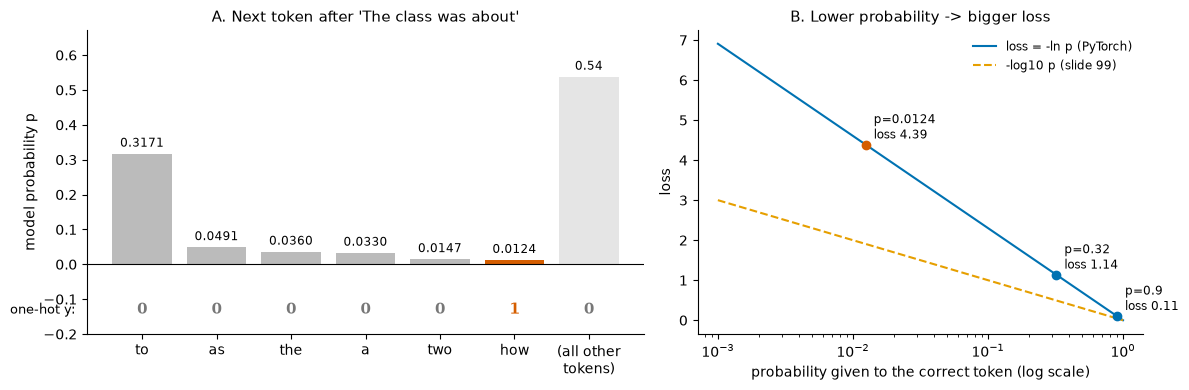

In [4]:
draw_ce(["to", "as", "the", "a", "two", "how"], [0.3171, 0.0491, 0.036, 0.033, 0.0147, 0.0124], correct="how")

**그림에서 볼 것**
- A: 모델은 "to"에 확률을 가장 많이 줬지만 정답은 "how"(빨강)입니다. 막대 아래 0과 1이 one-hot 벡터입니다.
- B: 정답에 준 확률이 낮을수록 손실이 가파르게 커집니다. 확률 0.9면 손실 0.11, 0.0124면 4.39입니다.
- B의 주황 점선은 밑이 10인 로그입니다. 슬라이드 99쪽의 1.907은 이 값입니다. PyTorch는 자연로그(파란 선)를 씁니다 [6]. 바로 아래 GPT-2 셀에서 손으로 구한 $-\ln p$가 PyTorch의 `F.cross_entropy` 값과 같은 것으로 확인합니다.

**식과 근거**: 슬라이드 100쪽의 식은 어휘 전체에 대해 쓴 꼴입니다 [1, 100쪽]. 아래는 자연로그로 쓴 것입니다.

$$\text{CE} = -\sum_{i \in \text{vocab}} y_i \ln p_i = -\ln p_{\text{정답}}$$

**직접 바꿔 보기**: 아래 `p`를 0.5, 0.01로 바꿔 두 로그 값이 어떻게 달라지는지 보세요.

In [5]:
p = 0.0124
print(f"-log10(p) = {-math.log10(p):.3f}   (슬라이드 99쪽 숫자)")
print(f"-ln(p)    = {-math.log(p):.3f}   (PyTorch가 쓰는 값)")
assert abs(-math.log10(p) - 1.907) < 1e-3

-log10(p) = 1.907   (슬라이드 99쪽 숫자)
-ln(p)    = 4.390   (PyTorch가 쓰는 값)


이번에는 GPT-2로 실제 문장의 토큰마다 손실을 구하고, 위 식을 그대로 쓴 값이 PyTorch, Hugging Face가 계산한 값과 같은지 확인합니다.

In [6]:
tok = AutoTokenizer.from_pretrained("openai-community/gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device).eval()

ids = tok("The class was about how agents work", return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    logits = gpt2(ids).logits[0, :-1]
target = ids[0, 1:]
probs = torch.softmax(logits, -1)
onehot = F.one_hot(target, probs.shape[-1]).float()
by_hand = -(onehot * probs.log()).sum(-1)                     # 슬라이드 100쪽 식 그대로
display(pd.DataFrame({"정답 토큰": [tok.decode(t) for t in target],
                      "P(정답)": probs[torch.arange(len(target)), target].cpu().numpy().round(4),
                      "손실 -ln P": by_hand.cpu().numpy().round(3)}))

assert torch.allclose(by_hand.mean(), F.cross_entropy(logits, target), atol=1e-4)
with torch.no_grad():
    assert abs(gpt2(ids, labels=ids).loss.item() - by_hand.mean().item()) < 1e-4
print("평균 손실:", round(by_hand.mean().item(), 3))

,정답 토큰,P(정답),손실 -ln P
0,class,0.0004,7.718
1,was,0.0555,2.891
2,about,0.0043,5.441
3,how,0.0133,4.317
4,agents,0.0001,9.258
5,work,0.0322,3.435


평균 손실: 5.51


이 노트북의 결과: GPT-2는 "how"에 0.013 정도를 줘서 슬라이드의 0.0124와 비슷합니다. 하지만 "agents"에는 0.0001밖에 주지 않아 손실이 9가 넘습니다. 문장 전체의 손실은 토큰별 손실의 평균입니다.

## 2. 경사 하강(gradient descent): 손실을 줄이는 방법

**한 줄 정의**: 손실이 줄어드는 쪽으로 파라미터를 조금씩 옮기는 것을 반복하는 방법입니다 [2].

**왜 필요한가**: 손실은 "얼마나 틀렸는지"만 알려 줍니다. 어느 쪽으로 고칠지는 손실 곡선의 **기울기**(slope, 여러 파라미터면 gradient)가 알려 줍니다. 기울기가 음수면 오른쪽으로 가야 손실이 줄고, 양수면 왼쪽으로 가야 줄어듭니다.

**숫자로 따라가기**: 파라미터가 하나뿐인 장난감 손실 $L(w) = (w-3)^2 + 1$을 생각합니다. 가장 낮은 곳은 $w=3$입니다. 기울기는 $2(w-3)$입니다. 한 번에 얼마나 움직일지를 정하는 수를 **학습률**(learning rate) $\eta$라고 합니다. $\eta=0.1$, $w=0$에서 시작하면:

| 걸음 | $w$ | 기울기 $2(w-3)$ | 다음 $w = w - 0.1 \times$ 기울기 |
|---|---|---|---|
| 0 | 0.000 | −6.00 | 0.600 |
| 1 | 0.600 | −4.80 | 1.080 |
| 2 | 1.080 | −3.84 | 1.464 |
| 3 | 1.464 | −3.07 | 1.771 |

기울기가 음수라 $w$가 오른쪽(3 쪽)으로 갑니다. 가까워질수록 기울기가 작아져 걸음도 작아집니다.

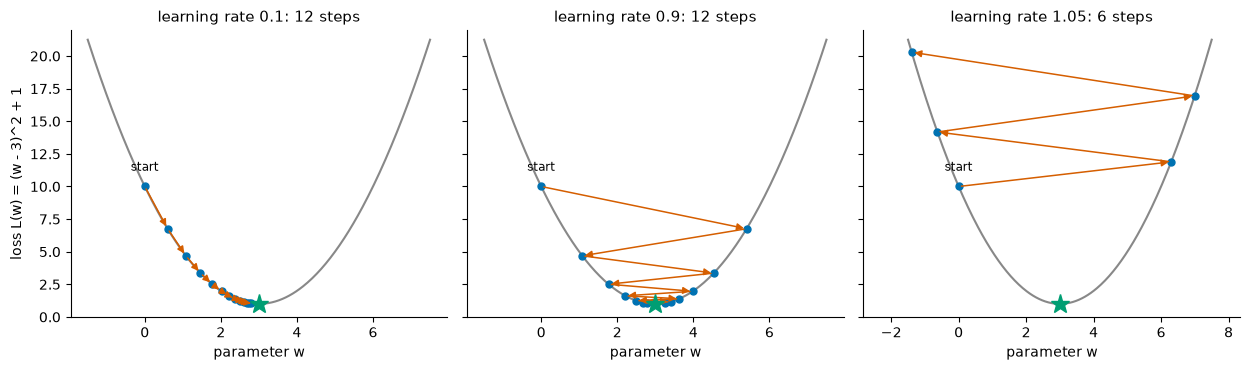

In [7]:
def descend(lr, w=0.0, steps=12):
    path = [w]
    for _ in range(steps):
        w = w - lr * 2 * (w - 3)          # 기울기 2(w-3) 의 반대 방향으로 lr 만큼
        path.append(w)
    return path

runs = [(0.1, descend(0.1)), (0.9, descend(0.9)), (1.05, descend(1.05, steps=6))]
draw_gd(runs)
assert abs(runs[0][1][1] - 0.6) < 1e-12 and abs(runs[0][1][-1] - 3) < 0.3   # 표와 같고, 3 근처로 간다
assert abs(runs[2][1][-1] - 3) > abs(runs[2][1][0] - 3)                       # 학습률이 너무 크면 멀어진다

**그림에서 볼 것**
- 왼쪽(학습률 0.1): 한 방향으로 차근차근 내려가 초록 별(가장 낮은 곳)에 다가갑니다.
- 가운데(0.9): 너무 크게 움직여 골짜기 양쪽을 오가며 튑니다. 그래도 점점 줄어듭니다.
- 오른쪽(1.05): 걸음이 너무 커서 오갈수록 더 멀어집니다(발산). 학습률이 너무 작으면 느리고, 너무 크면 튀거나 발산합니다 [2].

**식과 근거**: $w \leftarrow w - \eta \cdot \dfrac{dL}{dw}$ [2]. 실제 모델은 파라미터 수백만~수십억 개 각각의 기울기를 한 번에 계산합니다(PyTorch의 `loss.backward()`). 아래 실습 코드는 경사 하강을 고친 **AdamW**를 씁니다. AdamW는 Adam이라는 경사 하강 변형에서, 파라미터를 0 쪽으로 조금씩 줄이는 일(weight decay)을 손실에서 나온 업데이트와 따로 떼어 적용한 방법입니다 [16].

**직접 바꿔 보기**: `descend(0.5)`, `descend(0.01)`을 그려 보세요. 0.5는 한 번에 정답으로 가고(이 손실에서만 생기는 특별한 경우), 0.01은 아주 느립니다.

## 3. 사전 학습 데이터 거르기와 mid-training

### 데이터 파이프라인

**한 줄 정의**: 웹에서 모은 글을 학습에 쓸 수 있게 다듬는 단계들입니다. 슬라이드 102쪽의 순서는 HTML에서 글 뽑기 → 언어 판별 → 규칙 필터 → 품질 필터 → 중복 제거입니다 [1, 102쪽].

**왜 필요한가**: 웹 글에는 메뉴, 광고, 다른 언어, 똑같은 글의 복사본이 많습니다. 중복이 많은 데이터로 학습한 모델은 학습 글을 그대로 베껴 내는 경우가 많고, 중복을 지우면 그런 출력이 크게 줄고 더 적은 학습 걸음으로 같은 성능에 갑니다 [5]. 어떤 거르기를 하느냐에 따라 같은 크기 모델의 성능이 크게 달라지고, 특히 모델 기반 품질 필터가 중요하다는 보고가 있습니다 [4].

**숫자로 따라가기**: 글 10개로 슬라이드 순서를 따라 단계마다 몇 개가 남는지 셉니다. 품질 필터(좋은 글처럼 보이는지 점수를 매기는 모델)는 이 장난감에서 뺐습니다.

1. **글 뽑기**: HTML 태그를 지웁니다.
2. **언어 판별**: 영어만 남깁니다(여기서는 흔한 영어 단어와 프랑스어 단어 수를 비교하는 단순한 방법).
3. **규칙 필터**: 너무 짧은 글, 기호투성이 글, 같은 줄만 반복하는 글을 뺍니다.
4. **중복 제거**: 똑같은 글은 하나만 남깁니다(여기서는 글의 해시값으로 비교).

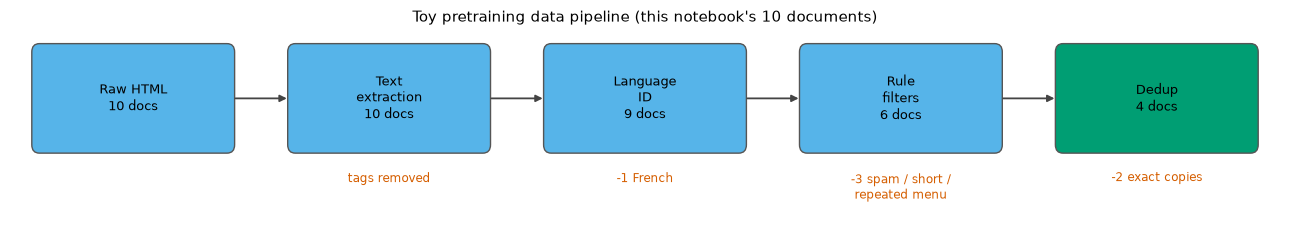

- Attention lets each token look at the earlier tokens in the text.
- A language model assigns a probability to the next token given the previous ones.
- Linear attention keeps a fixed size state, so the cost grows linearly with the length of the text.
- The KV cache stores keys and values so that the model does not recompute them for every new token.


In [8]:
raw = [
    "<html><body><p>Attention lets each token look at the earlier tokens in the text.</p></body></html>",
    "<html><body><p>Attention lets each token look at the earlier tokens in the text.</p></body></html>",
    "<div>A language model assigns a probability to the next token given the previous ones.</div>",
    "<p>CLICK HERE!!! $$$ ### @@@ >>> FREE $$$ !!! ### @@@</p>",
    "<p>ok thanks</p>",
    "<p>Le modèle de langue prédit le prochain mot à partir des mots précédents dans la phrase.</p>",
    "<ul><li>Home</li></ul>\n<ul><li>Home</li></ul>\n<ul><li>Home</li></ul>\n<ul><li>Home</li></ul>",
    "<p>Linear attention keeps a fixed size state, so the cost grows linearly with the length of the text.</p>",
    "<p>The KV cache stores keys and values so that the model does not recompute them for every new token.</p>",
    "<p>The KV cache stores keys and values so that the model does not recompute them for every new token.</p>",
]
EN = {"the", "a", "of", "to", "and", "in", "is", "that", "it", "for", "on", "with", "as", "at", "so", "by", "each", "given", "does", "not"}
FR = {"le", "la", "les", "de", "des", "du", "un", "une", "et", "à", "dans", "est", "pour", "sur"}

def extract(doc):
    lines = [html.unescape(re.sub(r"<[^>]+>", " ", l)) for l in doc.split("\n")]
    return "\n".join(" ".join(l.split()) for l in lines if l.strip())

def is_english(text):
    words = re.findall(r"\w+", text.lower())
    return sum(w in EN for w in words) >= sum(w in FR for w in words)

def passes_rules(text):
    words = text.split()
    letters = sum(c.isalpha() for c in text) / max(len(text.replace(" ", "")), 1)
    lines = text.split("\n")
    return len(words) >= 5 and letters >= 0.7 and len(set(lines)) / len(lines) > 0.5

stage = {"raw HTML": raw}
stage["text extraction"] = [extract(d) for d in raw]
stage["language ID"] = [t for t in stage["text extraction"] if is_english(t)]
stage["rule filters"] = [t for t in stage["language ID"] if passes_rules(t)]
seen, dedup = set(), []
for t in stage["rule filters"]:
    h = hashlib.sha1(t.lower().encode()).hexdigest()
    if h not in seen:
        seen.add(h); dedup.append(t)
stage["deduplication"] = dedup
counts = [len(v) for v in stage.values()]
assert counts == [10, 10, 9, 6, 4]

draw_pipeline(["Raw HTML", "Text\nextraction", "Language\nID", "Rule\nfilters", "Dedup"], counts,
              ["", "tags removed", "-1 French", "-3 spam / short /\nrepeated menu", "-2 exact copies"])
for t in stage["deduplication"]:
    print("-", t)

**그림에서 볼 것**
- 상자 안 숫자가 단계마다 남은 글 수입니다(이 노트북의 장난감 결과). 빨간 글씨가 그 단계에서 빠진 이유입니다.
- 10개 중 4개만 남았습니다. DataComp-LM은 Common Crawl에서 뽑은 240조(240T) 토큰을 출발점으로 두고, 거른 데이터 2.6조(2.6T) 토큰으로 7B 모델을 학습했습니다 [4].
- 실제 파이프라인은 여기에 더해 **비슷한 글**까지 찾는 중복 제거와, 좋은 글처럼 보이는지 점수를 매기는 **품질 분류 모델**을 씁니다 [4][5].

### data mixing과 mid-training

**한 줄 정의**: data mixing은 웹, 코드, 수학, 논문 같은 데이터 종류를 **어떤 비율로 섞을지** 정하는 일입니다 [1, 107쪽]. mid-training은 사전 학습 끝 무렵에 **목표 분야**(수학, 코드 등)의 비율을 높여 이어서 학습하는 단계입니다 [1, 108–111쪽].

**왜 필요한가**: 모델이 잘하길 바라는 분야의 데이터를 사전 학습 단계에서 더 많이 보여 주면 그 분야 성능에 도움이 되는 경향이 있다고 슬라이드는 소개합니다 [1, 110쪽]. 사전 학습 데이터와 사후 학습 데이터의 차이를 이어 주는 역할도 합니다 [1, 111쪽].

**숫자로 따라가기**: 아래 비율은 **설명을 위해 지어낸 예시**입니다. 실제 모델의 비율이 아닙니다. 웹 70%였던 것이 mid-training에서 35%로 줄고, 수학과 코드가 늘어나는 모습만 보세요.

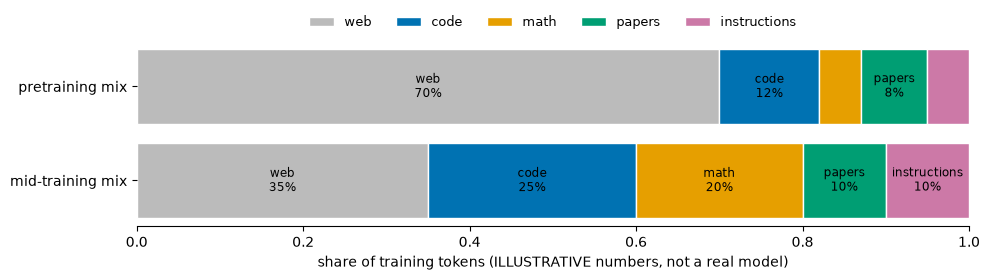

In [9]:
draw_mix({"pretraining mix": {"web": 0.70, "code": 0.12, "math": 0.05, "papers": 0.08, "instructions": 0.05},
          "mid-training mix": {"web": 0.35, "code": 0.25, "math": 0.20, "papers": 0.10, "instructions": 0.10}})

**그림에서 볼 것**
- 두 막대의 전체 길이(100%)는 같고, 안의 비율만 바뀝니다. "무엇을 더 보여 줄지"를 바꾸는 것이 mid-training입니다.
- 이 숫자는 예시입니다. 실제 비율은 모델마다 다르고 실험으로 정합니다 [1, 107쪽].

## 4. 작은 트랜스포머 사전 학습해 보기

셰익스피어 희곡 약 100만 글자(tiny-shakespeare [13])로 **글자 단위** 언어 모델을 처음부터 학습합니다.
토큰이 글자 하나라서 어휘가 65개뿐입니다. 구조는 A2의 GPT-2와 비슷하고 크기가 작습니다(층 4개, 차원 192). 다만 PyTorch의 `nn.TransformerEncoderLayer`를 쓰고, 입력 임베딩과 출력 층의 가중치를 같이 쓰지 않는 등 세부가 조금 다릅니다.

데이터는 **학습용**(앞 90%)과 **검증용**(뒤 10%)으로 나눕니다. 검증용 글은 학습에 쓰지 않고 "처음 보는 글을 얼마나 잘 맞히나"를 잴 때만 씁니다.

아무것도 학습하지 않은 모델은 65글자를 고르게 찍으므로 손실이 $\ln 65 \approx 4.17$ 근처에서 시작합니다.

In [10]:
path = "data/tinyshakespeare.txt"
if not os.path.exists(path):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", path)
text = open(path, encoding="utf-8").read()
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print(f"글자 수 {len(data):,}, 어휘 {len(chars)}개, 시작 손실 기대값 ln({len(chars)}) = {math.log(len(chars)):.2f}")

글자 수 1,115,394, 어휘 65개, 시작 손실 기대값 ln(65) = 4.17


In [11]:
BLOCK, BATCH = 128, 64

def get_batch(src):
    ix = torch.randint(len(src) - BLOCK - 1, (BATCH,))
    x = torch.stack([src[i:i + BLOCK] for i in ix])
    y = torch.stack([src[i + 1:i + BLOCK + 1] for i in ix])        # 한 글자씩 밀린 것이 정답
    return x.to(device), y.to(device)

class TinyGPT(nn.Module):
    def __init__(self, vocab, d=192, n_layer=4, n_head=6):
        super().__init__()
        self.tok = nn.Embedding(vocab, d)
        self.pos = nn.Embedding(BLOCK, d)
        layer = nn.TransformerEncoderLayer(d, n_head, 4 * d, dropout=0.1, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, n_layer, enable_nested_tensor=False)
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab)

    def forward(self, idx):
        T = idx.shape[1]
        x = self.tok(idx) + self.pos(torch.arange(T, device=idx.device))
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=idx.device)   # causal mask
        return self.head(self.ln(self.blocks(x, mask=mask, is_causal=True)))

@torch.no_grad()
def sample(m, n_chars=300, T=0.8, seed=0):
    m.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    idx = torch.tensor([[stoi["\n"]]], device=device)
    for _ in range(n_chars):
        logits = m(idx[:, -BLOCK:])[0, -1] / T
        idx = torch.cat([idx, torch.multinomial(torch.softmax(logits, -1), 1, generator=g)[None]], 1)
    m.train()
    return "".join(chars[i] for i in idx[0].tolist())

@torch.no_grad()
def eval_loss(m, src, n_batches=20):
    m.eval()
    out = np.mean([F.cross_entropy(m(x).flatten(0, 1), y.flatten()).item() for x, y in (get_batch(src) for _ in range(n_batches))])
    m.train()
    return out

def pretrain(m, src, steps, every=250, lr=1e-3):
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    log = []
    for step in range(steps + 1):
        if step % every == 0:
            log.append({"step": step, "train": eval_loss(m, src), "val": eval_loss(m, val_data)})
        if step == steps:
            break
        x, y = get_batch(src)
        loss = F.cross_entropy(m(x).flatten(0, 1), y.flatten())
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return pd.DataFrame(log)

torch.manual_seed(0)
tiny = TinyGPT(len(chars)).to(device)
print(f"파라미터 {sum(p.numel() for p in tiny.parameters()):,}개")
print("학습 전 샘플:\n", sample(tiny, 150))

파라미터 1,829,441개


학습 전 샘플:
 
PuaUU!IbnqeGCbeCS!RimZGLsAbiLEEXDSUA;BdSu3T?:iwxu.NnND.eEWT$EjgGtUDcJqi$JAbP'fKkXHd!kiNJuRg$ngYLIlltT?UW-i'ntLdunIICZhbSH&QtBtqQrE;yMrYj-LVSUS,FJhVISs


In [12]:
STEPS = 3000 if device == "cuda" else 300
t0 = time.time()
log_full = pretrain(tiny, train_data, STEPS)
print(f"{STEPS} 걸음, {time.time() - t0:.0f}초")
display(log_full.round(3).T)
print("학습 후 샘플:\n", sample(tiny, 400))
assert log_full["val"].iloc[-1] < log_full["val"].iloc[0] - 1.5
if device == "cuda":
    assert log_full["val"].iloc[-1] < 2.0

3000 걸음, 37초


,0,1,2,3,4,5,6,7,8,9,10,11,12
step,0.000,250.000,500.000,750.000,1000.000,1250.000,1500.000,1750.000,2000.000,2250.000,2500.000,2750.000,3000.000
train,4.343,2.054,1.717,1.562,1.496,1.438,1.393,1.368,1.353,1.337,1.325,1.328,1.324
val,4.346,2.109,1.857,1.739,1.674,1.625,1.602,1.565,1.577,1.546,1.538,1.546,1.550


학습 후 샘플:
 
A grace thee beat time by us with thee.

Nurse:
And we good my lord:
And say you she is the noble lose from the seal
As the battle you and in a garlish'd of what we blood.

STANLEY:
I have an cold you so thus, come you for cannot,
And fight thy low noble prayers are,
And by his fool dear lives from me as life;
Be the crown sovereign be rise, my feeling in and
The crief of this were ourselves best 


이 노트북의 결과: GPU에서 몇십 초(위에 찍힌 시간) 만에 등장인물 이름, 줄바꿈, 대사 형식을 흉내 냅니다. 뜻은 아직 엉망입니다.
실제 LLM은 같은 일을 훨씬 큰 규모로 합니다. 예를 들어 DataComp-LM의 7B 모델은 2.6조 토큰으로 학습했습니다 [4]. 이 실습은 100만 글자입니다.

## 5. 학습 손실과 검증 손실, 과적합

**한 줄 정의**: **학습 손실**은 학습에 쓴 글에서, **검증 손실**은 학습에 쓰지 않은 글에서 잰 손실입니다. **과적합**(overfitting)은 모델이 학습 글을 너무 그대로 외워서, 처음 보는 글은 오히려 못 맞히게 된 상태입니다 [3].

**왜 필요한가**: 학습 손실만 보면 "외운 것"과 "배운 것"을 구별할 수 없습니다. 두 손실이 같이 내려가면 배우는 중이고, 학습 손실은 계속 내려가는데 검증 손실이 다시 오르면 외우기 시작한 것입니다 [3].

**숫자로 따라가기**: 같은 모델을 이번에는 **글 1만 자**로만 학습합니다(위 실험의 1% 정도). 1만 자를 수천 번 반복해서 보게 되므로 외우기 쉬운 조건입니다. 위의 전체 데이터 실험과 나란히 그립니다.

3000 걸음, 37초


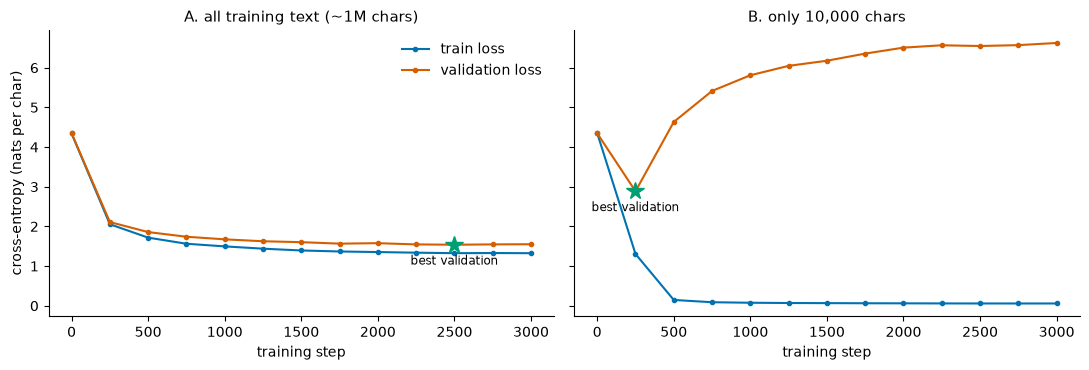

1만 자 학습: 마지막 학습 손실 0.06, 가장 낮던 검증 손실 2.89, 마지막 검증 손실 6.62


In [13]:
SMALL = 10_000
torch.manual_seed(0)
tiny_small = TinyGPT(len(chars)).to(device)
t0 = time.time()
log_small = pretrain(tiny_small, train_data[:SMALL], STEPS)
print(f"{STEPS} 걸음, {time.time() - t0:.0f}초")
draw_overfit(log_full, log_small, SMALL)
best = log_small["val"].min()
print(f"1만 자 학습: 마지막 학습 손실 {log_small['train'].iloc[-1]:.2f}, 가장 낮던 검증 손실 {best:.2f}, 마지막 검증 손실 {log_small['val'].iloc[-1]:.2f}")
assert log_small["val"].iloc[-1] > best + 0.05                                # 검증 손실이 바닥을 찍고 다시 오른다
assert log_small["train"].iloc[-1] < log_small["val"].iloc[-1] - 0.3          # 학습 손실과 큰 차이

**그림에서 볼 것**
- A(전체 데이터): 파랑(학습)과 빨강(검증)이 거의 붙어서 함께 내려갑니다. 배우는 중입니다.
- B(1만 자): 처음에는 같이 내려가다가, 초록 별 이후 검증 손실이 다시 오릅니다. 학습 손실은 계속 내려갑니다. 두 선이 벌어지는 것이 과적합입니다 [3].
- 그래서 학습할 때는 학습 손실만 보지 않고 검증 손실을 같이 봅니다 [3].

**직접 바꿔 보기**: `SMALL`을 100,000으로 바꾸면 벌어짐이 줄어드는지 보세요.

## 6. SFT: 지도 미세조정과 질문 토큰 masking (슬라이드 112–113쪽)

**한 줄 정의**: SFT(supervised fine-tuning)는 (질문, 모범 답) 쌍으로 추가 학습해 "답하는 형식"을 가르치는 것입니다 [1, 113쪽][8].

**왜 필요한가**: 사전 학습만 한 모델은 "글을 이어 쓰는" 모델이지 "질문에 답하는" 모델이 아닙니다. 아래에서 SFT 전 GPT-2의 덧셈 정답률이 0인 것을 볼 수 있습니다.

**숫자로 따라가기**: GPT-2에 두 자리 덧셈 문답을 가르칩니다. 예시 하나를 토큰으로 자르면 13개가 되고, 손실에 들어가는 것은 답 부분 2개(" 82"와 끝 표시)뿐입니다. 질문 토큰의 정답(label) 자리에는 `-100`을 넣습니다. PyTorch의 cross-entropy는 기본값으로 label이 `-100`인 자리를 무시합니다 [6].

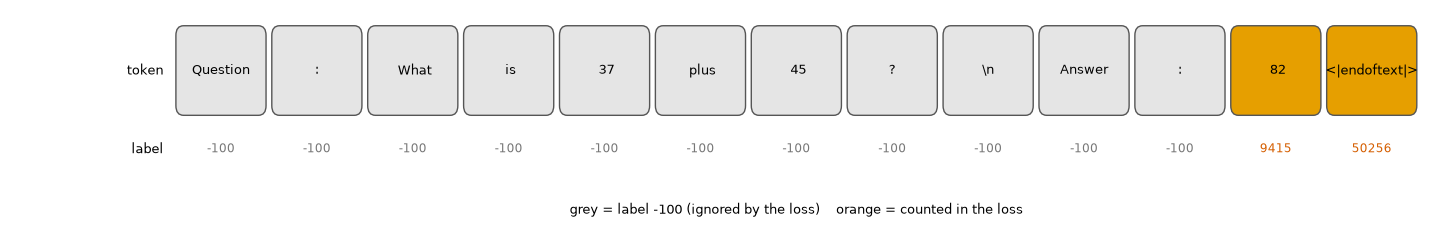

In [14]:
def make_prompt(a, b):
    return f"Question: What is {a} plus {b}?\nAnswer:"

all_pairs = [(a, b) for a in range(100) for b in range(100)]
random.Random(0).shuffle(all_pairs)
test_pairs, train_pairs = all_pairs[:300], all_pairs[300:]

def encode(a, b):
    p = tok(make_prompt(a, b)).input_ids
    t = tok(f" {a + b}").input_ids + [tok.eos_token_id]
    return p, t

def collate(pairs):
    ex = [encode(a, b) for a, b in pairs]
    L = max(len(p) + len(t) for p, t in ex)
    ids = torch.full((len(ex), L), tok.eos_token_id)
    labels = torch.full((len(ex), L), -100)
    attn = torch.zeros((len(ex), L), dtype=torch.long)
    for i, (p, t) in enumerate(ex):
        ids[i, :len(p) + len(t)] = torch.tensor(p + t)
        labels[i, len(p):len(p) + len(t)] = torch.tensor(t)       # 답 토큰만 손실에 넣는다
        attn[i, :len(p) + len(t)] = 1
    return ids.to(device), labels.to(device), attn.to(device)

ids, labels, _ = collate([(37, 45)])
draw_mask([tok.decode(t) for t in ids[0]], labels[0].tolist())
assert torch.nn.CrossEntropyLoss().ignore_index == -100          # PyTorch 기본값 [6]
assert (labels[0] != -100).sum().item() == 2

**그림에서 볼 것**
- 위 줄은 토큰, 아래 줄은 그 자리의 label입니다. label은 그 자리 토큰의 번호 그대로입니다(" 82" → 9415, 끝 표시 → 50256). "다음 토큰을 맞히도록 한 칸 밀기"는 모델 안에서 합니다. 그래서 Hugging Face 문서도 `labels = input_ids`로 둬도 된다고 적습니다 [15].
- 회색 칸(질문)은 label이 `-100`이라 손실에서 빠집니다. 주황 칸(답과 끝 표시)만 손실에 들어갑니다.
- 질문 부분은 매번 같은 문구라 모델이 맞히기 쉽습니다. 이것을 손실에서 빼면 학습 신호가 답에만 모입니다. 다만 질문 토큰까지 손실에 넣는 쪽이 오히려 나은 경우(답이 짧거나 데이터가 적을 때)도 보고되어 있어 정답이 하나는 아닙니다 [7].

In [15]:
tok.pad_token = tok.eos_token
tok.padding_side = "left"           # 여러 문장을 한꺼번에 생성할 때는 왼쪽을 채운다

@torch.no_grad()
def accuracy(m, pairs, bs=100):
    m.eval()
    correct = 0
    for i in range(0, len(pairs), bs):
        chunk = pairs[i:i + bs]
        enc = tok([make_prompt(a, b) for a, b in chunk], return_tensors="pt", padding=True).to(device)
        out = m.generate(**enc, max_new_tokens=5, do_sample=False, pad_token_id=tok.eos_token_id)
        for (a, b), s in zip(chunk, tok.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)):
            mm = re.match(r"\s*(\d+)", s)
            correct += bool(mm) and int(mm.group(1)) == a + b
    return correct / len(pairs)

sft = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device)
print("SFT 전 정답률:", accuracy(sft, test_pairs))

SFT 전 정답률: 0.0


In [16]:
SFT_STEPS = 600
opt = torch.optim.AdamW(sft.parameters(), lr=5e-5)
sft.train()
sft_log = []
for step in range(SFT_STEPS):
    batch = random.sample(train_pairs, 32)
    ids, labels, attn = collate(batch)
    loss = sft(input_ids=ids, attention_mask=attn, labels=labels).loss
    opt.zero_grad(); loss.backward(); opt.step()
    sft_log.append(loss.item())
acc_sft = accuracy(sft, test_pairs)
print(f"SFT {SFT_STEPS} 걸음 뒤 손실 {np.mean(sft_log[-20:]):.3f}, 처음 보는 문제 정답률 {acc_sft:.2f}")
assert acc_sft > 0.1

SFT 600 걸음 뒤 손실 0.818, 처음 보는 문제 정답률 0.52


이 노트북의 결과: 답하는 형식은 금방 배우지만, 계산은 일부만 맞힙니다. 이 정도 SFT로는 두 자리 덧셈 규칙을 완전히 익히지 못합니다.

## 7. RLHF: 사람의 선호로 학습 (슬라이드 114–115쪽)

**한 줄 정의**: 사람이 여러 답에 매긴 순위로 점수 모델(보상 모델)을 만들고, 언어 모델이 그 점수를 높이도록 강화학습하는 방법입니다 [8]. InstructGPT에서는 사람이 답 4~9개에 순위를 매기고, 이것을 두 개씩 짝지은 비교로 바꿔 보상 모델을 학습했습니다 [8, 3.5절].

**왜 필요한가**: 친절함, 안전함처럼 모범 답을 일일이 쓰기 어려운 것도, 여러 답 중 어느 것이 더 나은지는 사람이 비교적 쉽게 고를 수 있습니다.

**숫자로 따라가기**: 보상 모델은 답마다 점수 $r$을 냅니다. 답 A의 점수가 2.0, B가 0.5면, 사람이 A를 고를 확률을 $\sigma(2.0 - 0.5) = 1/(1+e^{-1.5}) \approx 0.82$로 봅니다. 점수 차이가 "A를 더 좋아할 확률"의 **로그 오즈**가 되도록 학습합니다 [8, 3.5절]. 로그 오즈는 확률 $q$를 $\ln\frac{q}{1-q}$로 바꾼 값입니다. $q=0.82$면 $\ln(0.82/0.18) \approx 1.5$로, 점수 차이와 같습니다.

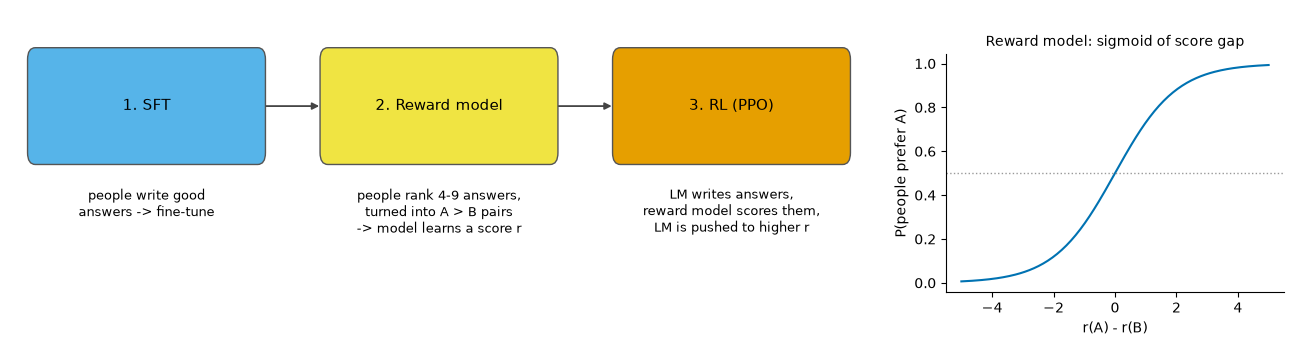

sigma(2.0 - 0.5) = 0.818


In [17]:
draw_rlhf()
print("sigma(2.0 - 0.5) =", round(1 / (1 + math.exp(-1.5)), 3))

**그림에서 볼 것**
- 왼쪽 세 상자가 InstructGPT 논문의 세 단계입니다: 모범 답으로 SFT → 사람이 순위를 매긴 비교 자료로 보상 모델 → 보상 모델 점수를 높이도록 강화학습(PPO) [8]. **PPO**는 강화학습 방법의 하나로, 답을 뽑아 보는 단계와 그 답으로 모델을 여러 번 고치는 단계를 번갈아 합니다 [17].
- 오른쪽 곡선: 점수 차이가 0이면 50%, 차이가 클수록 한쪽을 고를 확률이 1에 가까워집니다.
- 보상 모델을 학습한 뒤 강화학습하는 대신, 비교 자료로 언어 모델을 간단한 분류 손실 하나로 바로 학습하는 DPO라는 방법도 있습니다 [9].
- 한계(슬라이드 115쪽): 평가자가 틀리기도 하고, 사람마다 선호가 다르고, 모델이 듣기 좋은 말(아첨)을 하도록 잘못 유도될 수 있습니다 [1, 115쪽].

## 8. RLVR: 채점 가능한 보상 (슬라이드 116쪽)

**한 줄 정의**: 정답을 프로그램으로 확인할 수 있는 일(수학, 코드)에서, 맞으면 1, 틀리면 0을 보상으로 주는 강화학습입니다. Tülu 3 논문이 RLVR(reinforcement learning with verifiable rewards)이라는 이름을 붙였습니다 [10].

**왜 필요한가**: 사람의 평가와 그것으로 만든 보상 모델은 틀릴 수 있고, 모델을 잘못된 방향(예: 아첨)으로 이끌 수 있습니다 [1, 115쪽]. 채점기(verifier)는 단위 테스트, 정확히 일치, 증명 검사처럼 확인 방법이 정해져 있습니다 [1, 116쪽]. 대신 채점기를 잘 설계해야 합니다 [1, 116쪽].

**숫자로 따라가기**: 아래 RL 실험의 첫 걸음에서 실제로 나온 답 8개와 보상을 그림으로 봅니다(실험을 돌린 뒤 그립니다).

## 9. REINFORCE: 보상으로 확률을 미는 원리

**한 줄 정의**: 답을 뽑아 보고, 보상이 좋았던 답은 확률을 올리고 나빴던 답은 내리도록 기울기를 만드는 방법입니다 [12]. 아래에서는 보상의 평균을 기준으로 "좋았다/나빴다"를 정합니다 [11].

**왜 필요한가**: 강화학습에는 "정답 토큰"이 주어지지 않습니다. 모델이 직접 뽑은 답과 그 보상만 있습니다. REINFORCE는 그것만으로 기울기를 만듭니다.

**숫자로 따라가기**: 아주 작은 "모델"로 먼저 봅니다. 37 + 45에 대해 답 후보가 4개뿐이고, 모델은 처음에 틀린 답 "81"을 가장 좋아합니다.

1. 답 8개를 뽑습니다. "82"면 보상 1, 아니면 0.
2. 8개 보상의 평균을 뺍니다. 이 값을 **advantage**라고 합니다. 8개 중 2개가 맞았다면 평균 0.25, 맞은 답은 $1-0.25=+0.75$, 틀린 답은 $0-0.25=-0.25$입니다.
3. advantage만큼 그 답의 로그 확률을 올리거나 내립니다.

같은 문제의 답 묶음 평균을 기준(baseline)으로 쓰는 것이 GRPO의 핵심 생각입니다 [11]. 실제 GRPO는 평균을 뺀 뒤 묶음의 표준편차로 나누고, PPO처럼 확률 비율을 일정 범위로 잘라 주는 항과, 기준 모델에서 너무 멀어지지 않게 하는 KL 항을 더합니다 [11, 4.1절]. 이 노트북은 평균 빼기만 남긴 단순한 판입니다.

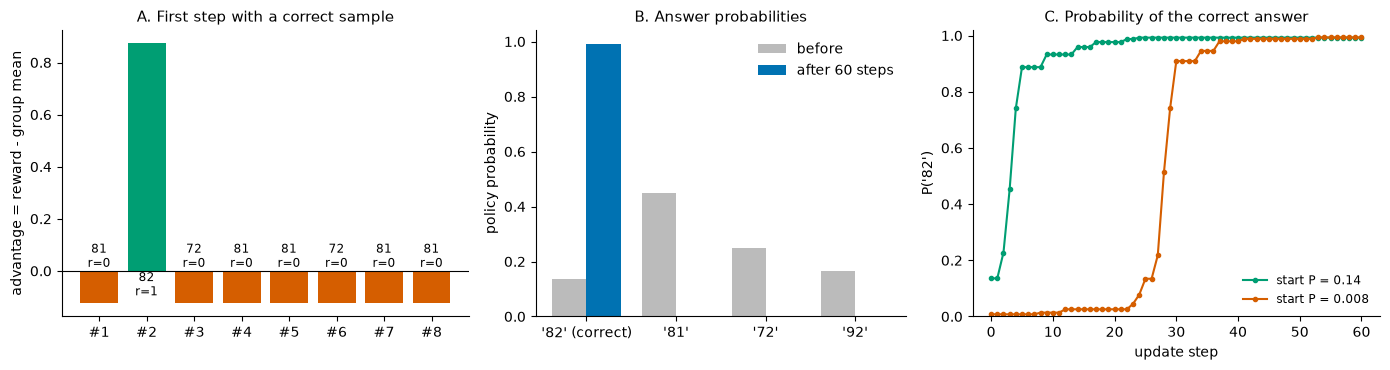

P('82') 0.5 넘는 걸음: 0.14 에서 시작 4걸음, 0.008 에서 시작 28걸음


In [18]:
names = ["82", "81", "72", "92"]                 # 0 번이 정답
softmax = lambda z: np.exp(z - z.max()) / np.exp(z - z.max()).sum()

def reinforce_toy(theta0, steps=60, seed=1, lr=0.5):
    theta = np.array([theta0, 1.2, 0.6, 0.2])    # 처음에는 '81' 을 가장 좋아한다
    rng = np.random.default_rng(seed)
    hist, first = [softmax(theta)], None
    for step in range(steps):
        probs_t = softmax(theta)
        s = rng.choice(4, size=8, p=probs_t)
        r = (s == 0).astype(float)
        adv = r - r.mean()                       # 묶음 평균을 뺀 advantage
        grad = sum(a * (np.eye(4)[k] - probs_t) for k, a in zip(s, adv))   # d log softmax / d theta
        theta = theta + lr * grad
        hist.append(softmax(theta))
        if first is None and r.sum() > 0:
            first = (s, r, adv)
    return np.array(hist), first

hist, first = reinforce_toy(0.0)                 # 정답 확률 0.14 에서 시작
hist_low, _ = reinforce_toy(-3.0)                # 정답 확률 0.008 에서 시작
draw_reinforce(names, *first, hist, hist_low)
reach = lambda h: int(np.argmax(h[:, 0] > 0.5)) if (h[:, 0] > 0.5).any() else len(h)
print(f"P('82') 0.5 넘는 걸음: 0.14 에서 시작 {reach(hist)}걸음, 0.008 에서 시작 {reach(hist_low)}걸음")
assert hist[0][0] < 0.25 and hist[-1][0] > 0.9
assert reach(hist_low) > reach(hist)             # 처음 확률이 낮으면 출발이 늦다

**그림에서 볼 것**
- A: 처음으로 정답이 하나라도 나온 걸음의 답 8개입니다. 정답(초록)은 위로, 틀린 답(빨강)은 아래로 밀립니다. 8개가 모두 틀리면 advantage가 전부 0이라 아무것도 배우지 않습니다.
- B: 업데이트 60번 뒤 정답 "82"의 확률이 가장 커졌습니다. 사람이 정답을 알려 준 적은 없고 "맞았다/틀렸다"만 줬습니다.
- C: 초록은 정답 확률 0.14에서, 빨강은 0.008에서 시작한 경우입니다. 빨강은 8개를 뽑아도 정답이 거의 나오지 않아 한동안 그대로 있다가, 정답이 몇 번 나온 뒤에야 오릅니다(위에 찍힌 걸음 수). 그래서 실제로는 SFT를 먼저 해서 가끔이라도 맞히게 만든 뒤 RL을 합니다.

**식과 근거**: 손실 $= -\sum_i (r_i - \bar r)\,\log P(\text{답}_i)$. 보상으로 기울기를 만드는 방법은 REINFORCE [12]에서, 묶음 평균을 빼는 방법은 GRPO [11]에서 온 것입니다. 이 손실을 줄이면 advantage가 양수인 답의 확률이 오릅니다.

**직접 바꿔 보기**: `reinforce_toy(-5.0)`처럼 더 낮은 곳에서 시작하거나, `lr`을 0.1로 줄여 보세요.

이제 같은 방법을 GPT-2에 씁니다. 위 장난감과 다른 점은 답이 토큰 여러 개라는 것뿐입니다. 답의 로그 확률은 답 토큰들의 로그 확률 합입니다.

1. 문제마다 답을 8개씩 **샘플링**합니다(temperature 1).
2. 맞으면 1, 틀리면 0. 같은 문제의 8개 평균을 빼서 advantage를 만듭니다.
3. 손실 $= -\sum (\text{advantage}) \times \log P(\text{답})$으로 경사 하강을 합니다.

SFT 모델에서 시작합니다(위 9절 C에서 본 이유).

RL 300 걸음, 70초


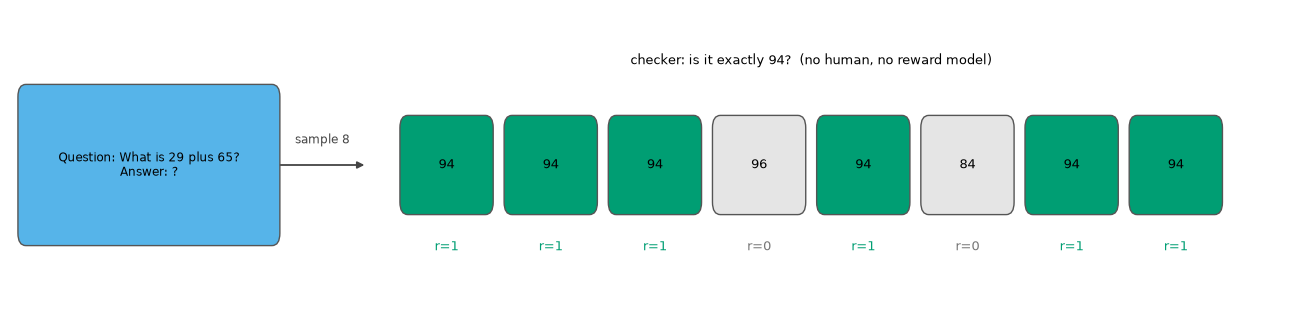

In [19]:
policy = copy.deepcopy(sft)
opt = torch.optim.AdamW(policy.parameters(), lr=2e-5)
G, N_PROMPTS, RL_STEPS = 8, 32, 300

rl_log = []
example = None
t0 = time.time()
for step in range(RL_STEPS):
    batch = random.sample(train_pairs, N_PROMPTS)
    enc = tok([make_prompt(a, b) for a, b in batch], return_tensors="pt", padding=True).to(device)
    P = enc.input_ids.shape[1]
    policy.eval()
    with torch.no_grad():
        out = policy.generate(**enc, max_new_tokens=5, do_sample=True, temperature=1.0, top_k=0,
                              num_return_sequences=G, pad_token_id=tok.eos_token_id)
    gen = out[:, P:]
    texts = tok.batch_decode(gen, skip_special_tokens=True)
    truth = [a + b for a, b in batch for _ in range(G)]
    reward = torch.tensor([float(bool(re.match(r"\s*(\d+)", s)) and int(re.match(r"\s*(\d+)", s).group(1)) == t)
                           for s, t in zip(texts, truth)], device=device)
    if example is None:
        example = (make_prompt(*batch[0]), texts[:G], truth[0], reward[:G].tolist())
    adv = (reward.view(N_PROMPTS, G) - reward.view(N_PROMPTS, G).mean(1, keepdim=True)).flatten()

    # 생성한 토큰 중 첫 <|endoftext|> 까지만 답으로 친다
    is_eos = (gen == tok.eos_token_id).long()
    gen_mask = ((is_eos.cumsum(1) - is_eos) == 0).float()
    attn = torch.cat([enc.attention_mask.repeat_interleave(G, 0), torch.ones_like(gen)], 1)
    pos = (attn.cumsum(1) - 1).clamp(min=0)
    policy.train()
    logits = policy(input_ids=out, attention_mask=attn, position_ids=pos).logits[:, P - 1:-1]
    logp = torch.log_softmax(logits.float(), -1).gather(-1, gen[..., None])[..., 0]
    loss = -(adv[:, None] * logp * gen_mask).sum() / gen_mask.sum()
    opt.zero_grad(); loss.backward(); opt.step()
    rl_log.append(reward.mean().item())
print(f"RL {RL_STEPS} 걸음, {time.time() - t0:.0f}초")
draw_rlvr(*example)

**그림에서 볼 것** (8절의 "숫자로 따라가기")
- 첫 걸음에서 실제로 나온 답 8개입니다. 초록이 채점기를 통과한 답(보상 1)입니다.
- 채점기는 "숫자가 정확히 같은가"만 봅니다. 사람도 보상 모델도 없습니다.

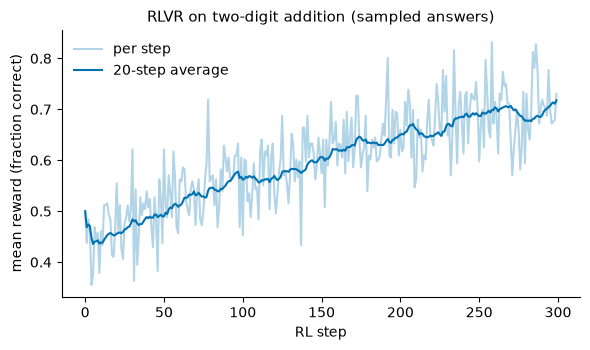

처음 보는 문제 정답률(greedy, 매번 가장 확률 높은 토큰을 고름): SFT 뒤 0.52 → RL 뒤 0.78
샘플 보상 평균: 처음 20걸음 0.45 → 마지막 20걸음 0.72


In [20]:
acc_rl = accuracy(policy, test_pairs)
smooth = pd.Series(rl_log).rolling(20, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(rl_log, alpha=0.3, color=OI["blue"], label="per step")
ax.plot(smooth, color=OI["blue"], label="20-step average")
ax.set_xlabel("RL step"); ax.set_ylabel("mean reward (fraction correct)")
ax.set_title("RLVR on two-digit addition (sampled answers)")
ax.legend(frameon=False); fig.tight_layout(); plt.show()
print(f"처음 보는 문제 정답률(greedy, 매번 가장 확률 높은 토큰을 고름): SFT 뒤 {acc_sft:.2f} → RL 뒤 {acc_rl:.2f}")
print(f"샘플 보상 평균: 처음 20걸음 {np.mean(rl_log[:20]):.2f} → 마지막 20걸음 {np.mean(rl_log[-20:]):.2f}")
assert np.mean(rl_log[-20:]) > np.mean(rl_log[:20])

**그림에서 볼 것**
- 연한 선은 걸음마다의 평균 보상, 진한 선은 20걸음 평균입니다. 오르는 방향은 9절 C의 장난감과 같지만, 300걸음에 걸쳐 천천히 오릅니다.
- 이 노트북의 결과: 사람이 모범 답을 더 주지 않았는데 "맞았는지"만 알려 줘도 정답률이 오릅니다.

### 에이전트용 학습 (슬라이드 117–118쪽)

SWE-smith는 파이썬 코드 저장소 하나마다 기존 테스트를 깨뜨리는 과제를 자동으로 수백~수천 개 만들고, 저장소 128개에서 모은 과제 5만 개를 코딩 에이전트 학습 데이터로 냈습니다 [14]. "테스트를 통과하는가"가 채점기 역할을 하므로, 위 덧셈 채점을 "테스트 통과"로 바꾼 것과 같은 생각입니다.

## 연습 문제

1. 어휘가 50,257개인 모델이 아무것도 모를 때(모든 토큰에 같은 확률) 손실은 얼마인가요?
2. 2절의 장난감 손실에서 학습률이 1.0이면 $w$는 어떻게 움직이나요? 손으로 두 걸음 계산해 보세요.
3. SFT에서 masking을 빼고(`labels`에 질문 토큰도 넣고) 학습하면 처음 보는 문제 정답률이 어떻게 될지 예상하고 직접 바꿔 보세요.
4. 9절에서 advantage 대신 보상 그대로(평균을 빼지 않고) 쓰면 틀린 답은 어떤 신호를 받나요?
5. 미적분 문제나 코드처럼 RLVR이 잘 맞는 일과, 소설 쓰기처럼 잘 안 맞는 일의 차이는 무엇인가요?

<details><summary>답 보기</summary>

1. $\ln 50257 \approx 10.8$입니다. GPT-2의 어휘 수는 위에서 불러온 토크나이저로 확인할 수 있습니다(`len(tok)`).
2. $w=0$에서 기울기 −6, $w \leftarrow 0 + 6 = 6$. $w=6$에서 기울기 6, $w \leftarrow 6 - 6 = 0$. 0과 6을 영원히 오갑니다(줄지도 늘지도 않음).
3. 결과는 설정에 따라 다릅니다. 손실의 많은 몫이 늘 같은 질문 문구를 맞히는 데 쓰이므로 답 학습이 느려질 수 있지만, 질문까지 학습하는 쪽이 나은 경우도 보고되어 있습니다 [7]. 직접 돌려 이 문제에서는 어떤지 확인해 보세요.
4. 보상 0인 틀린 답은 0 × log 확률 = 0이라 아무 신호도 받지 않습니다. 맞은 답만 밀려 올라가고 틀린 답은 직접 억제되지 않습니다. 평균을 빼면 틀린 답이 음수 신호를 받습니다.
5. 정답을 프로그램으로 확인할 수 있는지입니다. 확인할 수 없으면 사람의 선호나 보상 모델(RLHF)이 필요합니다.
</details>

## 정리

- 학습의 목표는 정답 토큰의 $-\ln p$ 평균(cross-entropy)을 줄이는 것입니다. 슬라이드의 1.907은 밑 10 로그 값입니다.
- 경사 하강은 기울기의 반대 방향으로 학습률만큼 움직이는 것을 반복합니다. 학습률이 너무 크면 튀거나 발산합니다.
- 검증 손실이 다시 오르면 과적합입니다. 학습 손실만 보면 알 수 없습니다.
- 사전 학습: 걸러 낸 대량의 글로 다음 토큰 맞히기. mid-training: 목표 분야 비율을 높여 이어 학습.
- SFT: 모범 답으로 형식과 행동을 가르칩니다. 흔히 질문 토큰은 손실에서 뺍니다(label −100).
- RLHF는 사람의 선호로 만든 보상 모델, RLVR은 자동 채점으로 보상을 줍니다. REINFORCE는 평균보다 나은 답의 확률을 올립니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| 1 | Diyi Yang, Michael Ryan, John Yang. *LLMs for Builders*, Stanford CS329Z Lecture 2 slides (2026), `data/lecture02.pdf`; [영상](https://youtu.be/Vr1NzH8bT44) | 슬라이드 17, 98–100쪽 예시 숫자, 102쪽 파이프라인 단계, 107–111쪽 data mixing·mid-training, 113–118쪽 SFT·RLHF 한계·RLVR·SWE-smith |
| 2 | Google. Machine Learning Crash Course: [Gradient descent](https://developers.google.com/machine-learning/crash-course/linear-regression/gradient-descent), [Hyperparameters](https://developers.google.com/machine-learning/crash-course/linear-regression/hyperparameters) (2026-11-13 확인) | 경사 하강 정의, 학습률이 너무 작거나 클 때 |
| 3 | Google. Machine Learning Crash Course: [Overfitting](https://developers.google.com/machine-learning/crash-course/overfitting/overfitting) (2026-11-13 확인) | 과적합 정의, 학습·검증 손실 곡선이 벌어지는 모습 |
| 4 | Li J, Fang A, Smyrnis G, et al. DataComp-LM: In search of the next generation of training sets for language models. [arXiv:2406.11794](https://arxiv.org/abs/2406.11794) (2024) | 중복 제거·필터·혼합, 모델 기반 품질 필터의 중요성 |
| 5 | Lee K, Ippolito D, Nystrom A, et al. Deduplicating Training Data Makes Language Models Better. [arXiv:2107.06499](https://arxiv.org/abs/2107.06499) (2021) | 중복이 그대로 베끼는 출력을 늘리고, 중복 제거가 이를 줄임 |
| 6 | PyTorch documentation, [`torch.nn.CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) (`ignore_index` 기본값 −100). 이 노트북에서 `assert`로 직접 확인 | 자연로그를 쓰는 손실, label −100 자리를 손실에서 뺌 |
| 7 | Shi Z, Yang AX, Wu B, et al. Instruction Tuning With Loss Over Instructions. [arXiv:2405.14394](https://arxiv.org/abs/2405.14394) (2024) | 질문 토큰까지 손실에 넣는 쪽이 나은 경우도 있음 |
| 8 | Ouyang L, Wu J, Jiang X, et al. Training language models to follow instructions with human feedback. [arXiv:2203.02155](https://arxiv.org/abs/2203.02155) (2022) | RLHF 세 단계(SFT, 보상 모델, PPO), 3.5절: 답 4~9개 순위를 짝 비교로 바꿈, 점수 차 = 선호의 로그 오즈 |
| 9 | Rafailov R, Sharma A, Mitchell E, et al. Direct Preference Optimization: Your Language Model is Secretly a Reward Model. [arXiv:2305.18290](https://arxiv.org/abs/2305.18290) (2023) | DPO: 간단한 분류 손실 하나로 선호를 학습 |
| 10 | Lambert N, Morrison J, Pyatkin V, et al. Tülu 3: Pushing Frontiers in Open Language Model Post-Training. [arXiv:2411.15124](https://arxiv.org/abs/2411.15124) (2024) | RLVR라는 이름 |
| 11 | Shao Z, Wang P, Zhu Q, et al. DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models. [arXiv:2402.03300](https://arxiv.org/abs/2402.03300) (2024) | GRPO(답 묶음 평균을 기준으로 쓰는 방법), 4.1절: 표준편차로 나누기, clip 항, KL 항 |
| 12 | Williams RJ. Simple statistical gradient-following algorithms for connectionist reinforcement learning. *Machine Learning* 8:229–256 (1992). [doi:10.1007/BF00992696](https://doi.org/10.1007/BF00992696). 서지 정보만 확인했고 본문은 열어 보지 못함 | REINFORCE(보상으로 기울기를 만드는 방법)의 원 논문 |
| 13 | Karpathy A. [char-rnn](https://github.com/karpathy/char-rnn), `data/tinyshakespeare` | 사전 학습 실습 데이터 |
| 14 | Yang J, Lieret K, Jimenez CE, et al. SWE-smith: Scaling Data for Software Engineering Agents. [arXiv:2504.21798](https://arxiv.org/abs/2504.21798) (2025) | 저장소마다 기존 테스트를 깨는 과제 수백~수천 개 자동 생성, 128개 저장소에서 5만 개 |
| 15 | Hugging Face Transformers documentation, [GPT-2](https://huggingface.co/docs/transformers/model_doc/gpt2) (`labels` 설명, 2026-11-13 확인) | label 은 모델 안에서 한 칸 밀림, `labels = input_ids` 로 둬도 됨 |
| 16 | Loshchilov I, Hutter F. Decoupled Weight Decay Regularization. [arXiv:1711.05101](https://arxiv.org/abs/1711.05101) (2017) | AdamW: weight decay 를 손실에서 나온 업데이트와 떼어 적용 |
| 17 | Schulman J, Wolski F, Dhariwal P, et al. Proximal Policy Optimization Algorithms. [arXiv:1707.06347](https://arxiv.org/abs/1707.06347) (2017) | PPO: 뽑기와 여러 번의 업데이트를 번갈아 함 |